# Three-seed SD/SI hand-only results

This notebook updates the paper-style reporting for the final hand-only grid: SD and SI, CNN1D/GCN/LSTM/Transformer, 10/20/30 frames, and seeds 7, 42, and 128. Every reported performance value is mean +/- sample standard deviation across the three matched seeds.

It follows the structure of Tables II, IV, and VI in `1571308763 paper-5.pdf`, while keeping the new repeated-seed analysis separate from the old single-seed tables. Run it from the repository root inside the Docker/Jupyter environment.

In [33]:
import json
from pathlib import Path
from shutil import copy2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
TEST_REPORT_DIR = ROOT / 'artifacts' / 'seed_reports_final3'
ROBUSTNESS_REPORT_DIR = ROOT / 'artifacts' / 'robustness_reports_multiseed'
OUTPUT_DIR = ROOT / 'artifacts' / 'final_reports'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ORDER = ['cnn1d', 'gcn', 'lstm', 'transformer']
MODEL_LABELS = {'cnn1d': 'CNN1D', 'gcn': 'GCN', 'lstm': 'LSTM', 'transformer': 'Transformer'}
SCENARIO_LABELS = {'sd': 'Signer-Dependent', 'si': 'Signer-Independent'}
FRAME_ORDER = [10, 20, 30]

def newest(pattern):
    paths = list(TEST_REPORT_DIR.glob(pattern))
    if not paths:
        raise FileNotFoundError(f'No files found for {pattern} in {TEST_REPORT_DIR}')
    return max(paths, key=lambda path: path.stat().st_mtime)

test_summary_path = newest('*_summary_mean_sd.csv')
test_selected_path = newest('*_selected_runs.csv')
pairwise_path = newest('*_pairwise_stats.csv')
robustness_summary_path = ROBUSTNESS_REPORT_DIR / 'robustness_summary.csv'
robustness_by_frame_path = ROBUSTNESS_REPORT_DIR / 'robustness_summary_by_frame.csv'
INFERENCE_REPORT_DIR = ROOT / 'artifacts' / 'inference_reports'
latency_by_seed_path = INFERENCE_REPORT_DIR / 'inference_latency_by_seed.csv'
latency_summary_path = INFERENCE_REPORT_DIR / 'inference_latency_summary.csv'

test_summary = pd.read_csv(test_summary_path)
test_summary['frame_sample_count'] = pd.to_numeric(test_summary['frame_sample_count'], errors='coerce')
test_runs = pd.read_csv(test_selected_path)
pairwise_stats = pd.read_csv(pairwise_path)
robustness_runs = pd.read_csv(robustness_summary_path)
robustness_summary = pd.read_csv(robustness_by_frame_path)
latency_by_seed = pd.read_csv(latency_by_seed_path)
latency_summary = pd.read_csv(latency_summary_path)

test_by_frame = test_summary.loc[test_summary['summary_scope'].eq('by_frame')].copy()

# Training values are the final metrics recorded by the trainer for each selected run.
training_rows = []
run_histories = {}
for run in test_runs.itertuples(index=False):
    history_path = Path(run.run_dir) / 'history.json'
    history = json.loads(history_path.read_text(encoding='utf-8'))
    run_histories[run.run_dir] = history
    training_rows.append({
        'scenario': run.scenario,
        'model': run.model,
        'frame_sample_count': int(run.frame_sample_count),
        'seed': int(run.seed),
        'run_dir': run.run_dir,
        'train_accuracy': history['accuracy'][-1],
        'train_f1_score': history['f1_score'][-1],
        'train_loss': history['loss'][-1],
        'test_accuracy': run.accuracy,
        'test_f1_score': run.f1_score,
        'test_loss': run.loss,
    })
training_testing_by_seed = pd.DataFrame(training_rows)
training_testing_summary = (
    training_testing_by_seed
    .groupby(['scenario', 'model', 'frame_sample_count'], as_index=False)
    .agg(
        n_seeds=('seed', 'nunique'),
        train_accuracy_mean=('train_accuracy', 'mean'), train_accuracy_std=('train_accuracy', 'std'),
        train_f1_score_mean=('train_f1_score', 'mean'), train_f1_score_std=('train_f1_score', 'std'),
        train_loss_mean=('train_loss', 'mean'), train_loss_std=('train_loss', 'std'),
        test_accuracy_mean=('test_accuracy', 'mean'), test_accuracy_std=('test_accuracy', 'std'),
        test_f1_score_mean=('test_f1_score', 'mean'), test_f1_score_std=('test_f1_score', 'std'),
        test_loss_mean=('test_loss', 'mean'), test_loss_std=('test_loss', 'std'),
    )
)
assert len(test_runs) == 72, f'Expected 72 selected test runs, found {len(test_runs)}'
assert len(robustness_runs) == 72, f'Expected 72 robustness runs, found {len(robustness_runs)}'
assert set(test_runs['seed']) == {7, 42, 128}
assert set(robustness_runs['seed']) == {7, 42, 128}
assert len(training_testing_by_seed) == 72
assert (training_testing_summary['n_seeds'] == 3).all()
assert len(latency_by_seed) == 72, f'Expected 72 latency runs, found {len(latency_by_seed)}'
assert (latency_summary['n_seeds'] == 3).all()
print(f'Test report: {test_summary_path.name}')
print(f'Test runs: {len(test_runs)} | Robustness runs: {len(robustness_runs)} | Latency runs: {len(latency_by_seed)}')

Test report: hand_sd_si_3seed_20261019T164232Z_summary_mean_sd.csv
Test runs: 72 | Robustness runs: 72 | Latency runs: 72


In [34]:
def mean_sd(row, metric, decimals=4):
    return f"{row[f'{metric}_mean']:.{decimals}f} +/- {row[f'{metric}_std']:.{decimals}f}"

def robustness_mean_sd(row, metric, decimals=4):
    return f"{row[f'{metric}_mean']:.{decimals}f} +/- {row[f'{metric}_sd']:.{decimals}f}"

def bold_best_means(table, higher_is_better=True):
    result = table.copy()
    numeric = result.attrs.get('numeric', {})
    for row_index, values in numeric.items():
        valid = {column: value for column, value in values.items() if pd.notna(value)}
        if not valid:
            continue
        best = max(valid.values()) if higher_is_better else min(valid.values())
        for column, value in valid.items():
            if value == best:
                result.loc[row_index, column] = f'**{result.loc[row_index, column]}**'
    return result


## Manuscript revision map

Use this notebook to replace the single-seed numerical evidence in the paper. Tables II-VI use the final clean hand-only grid and report mean +/- sample SD across seeds 7, 42, and 128. Table I and Fig. 2 remain method figures; update Table I wording to describe the combined full-frame visual effect and localized fixed-position occlusion.

In [35]:
manuscript_update_map = pd.DataFrame([
    ('Table I', 'Keep structure; revise robustness-condition wording.', 'Methods'),
    ('Table II', 'Replace 10-frame single-seed test results with mean +/- SD.', 'table_ii_10frame_test'),
    ('Table III', 'Replace 10-frame latency with current CUDA mean +/- SD, min, and max.', 'table_iii_10frame_latency'),
    ('Table IV', 'Report held-out test Accuracy and Macro F1 by frame as mean +/- SD.', 'table_iv_frame_comparison'),
    ('Table V', 'Replace frame-length latency values with current three-seed measurements.', 'table_v_latency_by_frame'),
    ('Table VI', 'Replace noisy-data results with mean +/- SD over 13,012 videos.', 'table_vi_robustness'),
    ('Fig. 3', 'Use the unique-person noisy-sample montage and revised caption.', 'representative_noisy_samples_unique.png'),
    ('Fig. 4', 'Replace single-run instability plot with clean-versus-robustness F1 error bars.', 'figure_4_clean_vs_robustness_f1.png'),
], columns=['Paper item', 'Required update', 'Notebook/export source'])
display(manuscript_update_map)

,Paper item,Required update,Notebook/export source
0,Table I,Keep structure; revise robustness-condition wo...,Methods
1,Table II,Replace 10-frame single-seed test results with...,table_ii_10frame_test
2,Table III,Replace 10-frame latency with current CUDA mea...,table_iii_10frame_latency
3,Table IV,Report held-out test Accuracy and Macro F1 by ...,table_iv_frame_comparison
4,Table V,Replace frame-length latency values with curre...,table_v_latency_by_frame
5,Table VI,Replace noisy-data results with mean +/- SD ov...,table_vi_robustness
6,Fig. 3,Use the unique-person noisy-sample montage and...,representative_noisy_samples_unique.png
7,Fig. 4,Replace single-run instability plot with clean...,figure_4_clean_vs_robustness_f1.png


## Table II replacement: 10-frame held-out test results

The table retains the original paper layout, but now reports mean +/- SD over three seeds. Bold indicates the best mean for each scenario-metric row; lowest loss is best.

In [36]:
def table_ii(frame_count=10):
    subset = test_by_frame.loc[test_by_frame['frame_sample_count'].eq(frame_count)]
    rows, numeric = [], {}
    for scenario in ['sd', 'si']:
        for metric, label, higher in [
            ('accuracy', 'Test Acc.', True),
            ('f1_score', 'Test F1', True),
            ('loss', 'Test Loss', False),
        ]:
            row = {'Scenario': SCENARIO_LABELS[scenario], 'Metric': label}
            values = {}
            for model in MODEL_ORDER:
                item = subset.loc[(subset['scenario'].eq(scenario)) & (subset['model'].eq(model))].iloc[0]
                row[MODEL_LABELS[model]] = mean_sd(item, metric)
                values[MODEL_LABELS[model]] = item[f'{metric}_mean']
            rows.append(row)
            numeric[len(rows) - 1] = values
    table = pd.DataFrame(rows)
    table.attrs['numeric'] = numeric
    return table

table_ii_10 = table_ii(10)
display(table_ii_10)
print('Apply bold within each row manually in the manuscript after choosing the correct direction for the metric.')

,Scenario,Metric,CNN1D,GCN,LSTM,Transformer
0,Signer-Dependent,Test Acc.,0.2203 +/- 0.0189,0.2166 +/- 0.0099,0.2314 +/- 0.0052,0.3995 +/- 0.0007
1,Signer-Dependent,Test F1,0.2125 +/- 0.0196,0.2078 +/- 0.0099,0.2255 +/- 0.0052,0.3928 +/- 0.0004
2,Signer-Dependent,Test Loss,5.1912 +/- 0.0500,4.8969 +/- 0.1022,5.1241 +/- 0.0115,3.2394 +/- 0.0286
3,Signer-Independent,Test Acc.,0.2195 +/- 0.0088,0.2185 +/- 0.0021,0.2228 +/- 0.0027,0.3731 +/- 0.0025
4,Signer-Independent,Test F1,0.2129 +/- 0.0090,0.2112 +/- 0.0040,0.2175 +/- 0.0029,0.3681 +/- 0.0029
5,Signer-Independent,Test Loss,5.2770 +/- 0.0246,4.9534 +/- 0.1516,5.2932 +/- 0.0773,3.3847 +/- 0.0696


Apply bold within each row manually in the manuscript after choosing the correct direction for the metric.


## Table IV replacement: training and held-out test comparison

Each `Tr./Te.` cell reports mean +/- sample SD across the three matched seeds (`7`, `42`, and `128`). `Tr.` is the final training metric recorded in each run's `history.json`; `Te.` is the corresponding fixed held-out test metric. The training values are not a separate post-training full-training-set inference evaluation.

In [37]:
def train_test_cell(item, metric):
    return (
        f"{item[f'train_{metric}_mean']:.4f} +/- {item[f'train_{metric}_std']:.4f} / "
        f"{item[f'test_{metric}_mean']:.4f} +/- {item[f'test_{metric}_std']:.4f}"
    )

def table_iv():
    rows = []
    for model in MODEL_ORDER:
        for frame_count in FRAME_ORDER:
            row = {'Model': MODEL_LABELS[model], 'Fr.': frame_count}
            for scenario, prefix in [('sd', 'SD'), ('si', 'SI')]:
                item = training_testing_summary.loc[
                    (training_testing_summary['scenario'].eq(scenario))
                    & (training_testing_summary['model'].eq(model))
                    & (training_testing_summary['frame_sample_count'].eq(frame_count))
                ].iloc[0]
                row[f'{prefix} Acc. Tr./Te.'] = train_test_cell(item, 'accuracy')
                row[f'{prefix} F1 Tr./Te.'] = train_test_cell(item, 'f1_score')
            rows.append(row)
    return pd.DataFrame(rows)

table_iv_frame = table_iv()
display(table_iv_frame)

,Model,Fr.,SD Acc. Tr./Te.,SD F1 Tr./Te.,SI Acc. Tr./Te.,SI F1 Tr./Te.
0,CNN1D,10,0.4651 +/- 0.0529 / 0.2203 +/- 0.0189,0.3970 +/- 0.0483 / 0.2125 +/- 0.0196,0.5006 +/- 0.0293 / 0.2195 +/- 0.0088,0.4304 +/- 0.0261 / 0.2129 +/- 0.0090
1,CNN1D,20,0.5989 +/- 0.0109 / 0.2774 +/- 0.0016,0.5262 +/- 0.0080 / 0.2715 +/- 0.0014,0.5902 +/- 0.0341 / 0.2610 +/- 0.0034,0.5167 +/- 0.0310 / 0.2570 +/- 0.0038
2,CNN1D,30,0.5455 +/- 0.0272 / 0.2478 +/- 0.0068,0.4674 +/- 0.0233 / 0.2424 +/- 0.0073,0.6026 +/- 0.0286 / 0.2511 +/- 0.0072,0.5297 +/- 0.0250 / 0.2470 +/- 0.0068
3,GCN,10,0.4066 +/- 0.0164 / 0.2166 +/- 0.0099,0.3402 +/- 0.0119 / 0.2078 +/- 0.0099,0.4183 +/- 0.0094 / 0.2185 +/- 0.0021,0.3500 +/- 0.0075 / 0.2112 +/- 0.0040
4,GCN,20,0.4566 +/- 0.0204 / 0.2477 +/- 0.0137,0.3886 +/- 0.0200 / 0.2405 +/- 0.0136,0.4539 +/- 0.0274 / 0.2391 +/- 0.0309,0.3841 +/- 0.0261 / 0.2329 +/- 0.0305
5,GCN,30,0.4531 +/- 0.0687 / 0.2390 +/- 0.0461,0.3879 +/- 0.0616 / 0.2329 +/- 0.0467,0.4981 +/- 0.0116 / 0.2502 +/- 0.0199,0.4278 +/- 0.0072 / 0.2445 +/- 0.0186
6,LSTM,10,0.6318 +/- 0.0404 / 0.2314 +/- 0.0052,0.5504 +/- 0.0390 / 0.2255 +/- 0.0052,0.6571 +/- 0.0162 / 0.2228 +/- 0.0027,0.5795 +/- 0.0176 / 0.2175 +/- 0.0029
7,LSTM,20,0.8119 +/- 0.0165 / 0.3317 +/- 0.0051,0.7263 +/- 0.0168 / 0.3264 +/- 0.0051,0.8427 +/- 0.0153 / 0.2947 +/- 0.0048,0.7666 +/- 0.0156 / 0.2915 +/- 0.0043
8,LSTM,30,0.8527 +/- 0.0156 / 0.3524 +/- 0.0098,0.7720 +/- 0.0172 / 0.3480 +/- 0.0100,0.8772 +/- 0.0219 / 0.3137 +/- 0.0012,0.8000 +/- 0.0213 / 0.3108 +/- 0.0015
9,Transformer,10,0.9150 +/- 0.0153 / 0.3995 +/- 0.0007,0.8342 +/- 0.0163 / 0.3928 +/- 0.0004,0.8956 +/- 0.0154 / 0.3731 +/- 0.0025,0.8200 +/- 0.0194 / 0.3681 +/- 0.0029


## Table III and Table V replacements: inference latency

Latency is measured during testing as model-only, batch-size-one inference on a preprocessed held-out test sample. Disk loading and feature extraction are excluded. Each seed is warmed up for 20 predictions, then timed for 100 predictions with CUDA synchronization before and after every call. Mean +/- SD is across the three seed-specific mean latencies.

In [38]:
def latency_value(scenario, model, frame_count):
    return latency_summary.loc[
        (latency_summary['scenario'].eq(scenario))
        & (latency_summary['model'].eq(model))
        & (latency_summary['frame_sample_count'].eq(frame_count))
    ].iloc[0]

def table_iii(frame_count=10):
    rows = []
    for model in MODEL_ORDER:
        for scenario in ['sd', 'si']:
            item = latency_value(scenario, model, frame_count)
            rows.append({
                'Model': MODEL_LABELS[model],
                'Scenario': scenario.upper(),
                'Mean Time (ms)': item['mean_time_ms_pm_sd'],
                'Min Time (ms)': f"{item['min_time_ms']:.3f}",
                'Max Time (ms)': f"{item['max_time_ms']:.3f}",
            })
    return pd.DataFrame(rows)

def table_v():
    rows = []
    for model in MODEL_ORDER:
        row = {'Model': MODEL_LABELS[model]}
        for frame_count in FRAME_ORDER:
            sd = latency_value('sd', model, frame_count)['mean_time_ms_pm_sd']
            si = latency_value('si', model, frame_count)['mean_time_ms_pm_sd']
            row[f'{frame_count} Fr. SD / SI (ms)'] = f'{sd} / {si}'
        rows.append(row)
    return pd.DataFrame(rows)

table_iii_latency = table_iii(10)
table_v_latency = table_v()
display(table_iii_latency)
display(table_v_latency)

,Model,Scenario,Mean Time (ms),Min Time (ms),Max Time (ms)
0,CNN1D,SD,1.355 +/- 0.021,1.243,1.885
1,CNN1D,SI,1.393 +/- 0.029,1.275,2.048
2,GCN,SD,1.824 +/- 0.023,1.691,2.636
3,GCN,SI,1.807 +/- 0.026,1.697,2.691
4,LSTM,SD,2.306 +/- 0.033,2.113,3.349
5,LSTM,SI,2.335 +/- 0.025,2.213,3.236
6,Transformer,SD,4.473 +/- 0.145,4.207,6.021
7,Transformer,SI,4.470 +/- 0.016,4.206,5.557


,Model,10 Fr. SD / SI (ms),20 Fr. SD / SI (ms),30 Fr. SD / SI (ms)
0,CNN1D,1.355 +/- 0.021 / 1.393 +/- 0.029,1.363 +/- 0.015 / 1.395 +/- 0.022,1.363 +/- 0.007 / 1.353 +/- 0.005
1,GCN,1.824 +/- 0.023 / 1.807 +/- 0.026,1.791 +/- 0.006 / 1.793 +/- 0.033,1.796 +/- 0.027 / 1.837 +/- 0.037
2,LSTM,2.306 +/- 0.033 / 2.335 +/- 0.025,2.438 +/- 0.136 / 2.284 +/- 0.031,2.308 +/- 0.049 / 2.332 +/- 0.060
3,Transformer,4.473 +/- 0.145 / 4.470 +/- 0.016,4.576 +/- 0.065 / 4.586 +/- 0.155,4.531 +/- 0.033 / 4.508 +/- 0.033


## Table VI replacement: noisy-data robustness

Robustness is evaluated on the 13,012 generated noisy videos. Values are mean +/- SD across the same three model seeds.

In [39]:
def table_vi():
    rows = []
    for scenario in ['sd', 'si']:
        for model in MODEL_ORDER:
            for frame_count in FRAME_ORDER:
                item = robustness_summary.loc[
                    (robustness_summary['scenario'].eq(scenario))
                    & (robustness_summary['model'].eq(model))
                    & (robustness_summary['frame_sample_count'].eq(frame_count))
                ].iloc[0]
                rows.append({
                    'Scenario': SCENARIO_LABELS[scenario],
                    'Model': MODEL_LABELS[model],
                    'Fr.': frame_count,
                    'Acc.': robustness_mean_sd(item, 'accuracy'),
                    'F1': robustness_mean_sd(item, 'f1_score'),
                    'Conf.': robustness_mean_sd(item, 'confidence'),
                    'Loss': robustness_mean_sd(item, 'loss'),
                })
    return pd.DataFrame(rows)

table_vi_robustness = table_vi()
display(table_vi_robustness)

,Scenario,Model,Fr.,Acc.,F1,Conf.,Loss
0,Signer-Dependent,CNN1D,10,0.1233 +/- 0.0092,0.1173 +/- 0.0101,0.3145 +/- 0.0388,7.7607 +/- 0.2495
1,Signer-Dependent,CNN1D,20,0.1582 +/- 0.0012,0.1518 +/- 0.0019,0.4199 +/- 0.0053,7.7270 +/- 0.1092
2,Signer-Dependent,CNN1D,30,0.1428 +/- 0.0042,0.1354 +/- 0.0052,0.3792 +/- 0.0256,7.4859 +/- 0.2069
3,Signer-Dependent,GCN,10,0.1259 +/- 0.0069,0.1191 +/- 0.0067,0.3013 +/- 0.0152,7.3455 +/- 0.0969
4,Signer-Dependent,GCN,20,0.1457 +/- 0.0135,0.1365 +/- 0.0132,0.3481 +/- 0.0184,7.1655 +/- 0.2624
5,Signer-Dependent,GCN,30,0.1434 +/- 0.0315,0.1351 +/- 0.0311,0.3477 +/- 0.0461,7.1471 +/- 0.4952
6,Signer-Dependent,LSTM,10,0.1284 +/- 0.0059,0.1232 +/- 0.0057,0.3803 +/- 0.0188,7.7038 +/- 0.0299
7,Signer-Dependent,LSTM,20,0.1847 +/- 0.0033,0.1783 +/- 0.0023,0.5055 +/- 0.0142,7.3119 +/- 0.1717
8,Signer-Dependent,LSTM,30,0.1941 +/- 0.0079,0.1878 +/- 0.0070,0.5330 +/- 0.0085,7.1793 +/- 0.1873
9,Signer-Dependent,Transformer,10,0.2327 +/- 0.0009,0.2264 +/- 0.0011,0.4102 +/- 0.0144,5.1609 +/- 0.0437


## Figure 3 replacement: representative noisy samples

Suggested caption: **Representative noisy test samples generated by a randomized full-frame visual effect and a temporary localized occlusion near the signing hand.** Each tile uses a different participant.

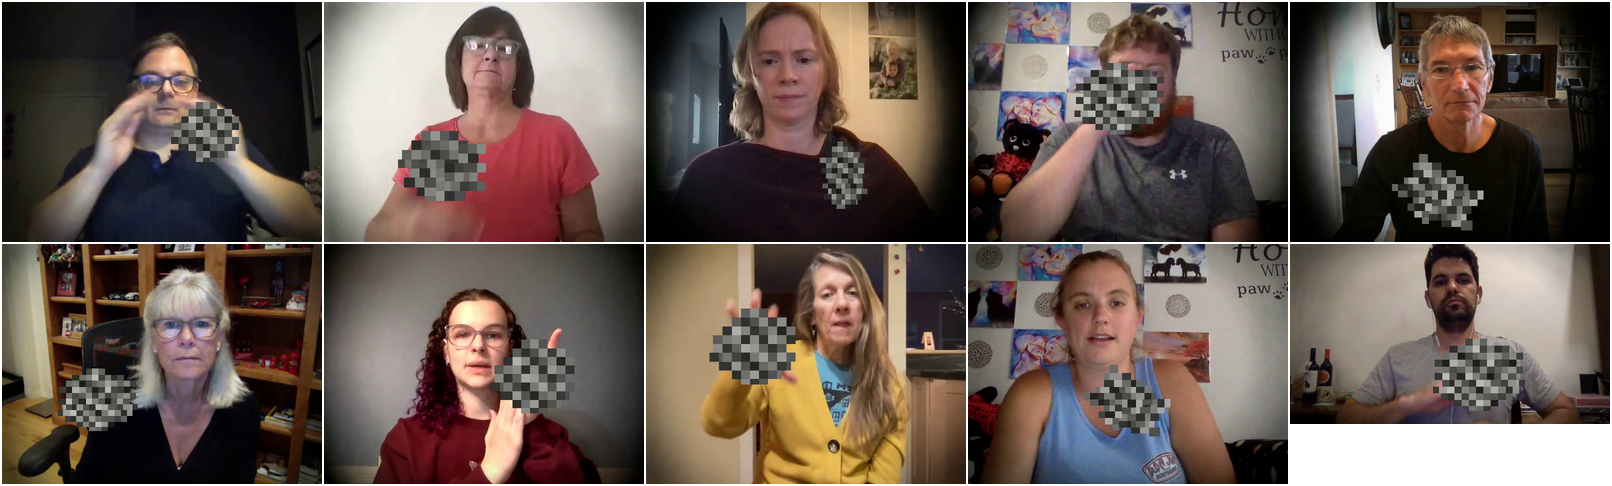

In [40]:
figure_3_path = ROOT / 'artifacts' / 'robustness_reports_old' / 'representative_noisy_samples_unique.png'
if not figure_3_path.exists():
    raise FileNotFoundError(f'Missing Figure 3 montage: {figure_3_path}')
figure_3_export_path = OUTPUT_DIR / 'figure_3_representative_noisy_samples.png'
copy2(figure_3_path, figure_3_export_path)
display(Image(filename=str(figure_3_export_path)))

## Figure 4 replacement: clean versus robustness Macro F1

Suggested caption: **Held-out test and noisy-data robustness Macro F1 across frame counts. Error bars show mean +/- standard deviation across three matched random-initialization seeds.** This replaces the earlier single-run Transformer instability plot.

## Seed-aware comparisons and test-to-robustness change

Paired tests remain exploratory because there are only three matched seeds. Holm-adjusted p-values are retained for transparency.

,scenario,model,frame_sample_count,accuracy_change,f1_change
0,sd,cnn1d,10.0,-0.097024,-0.095255
4,sd,cnn1d,20.0,-0.119226,-0.119713
8,sd,cnn1d,30.0,-0.104990,-0.106935
3,sd,gcn,10.0,-0.090733,-0.088672
7,sd,gcn,20.0,-0.102035,-0.103914
11,sd,gcn,30.0,-0.095674,-0.097807
1,sd,lstm,10.0,-0.103021,-0.102327
5,sd,lstm,20.0,-0.146973,-0.148094
9,sd,lstm,30.0,-0.158294,-0.160217
2,sd,transformer,10.0,-0.166764,-0.166400


,scenario,frame_sample_count,metric,model_a,model_b,mean_difference_a_minus_b,cohens_dz,paired_t_holm_p,wilcoxon_holm_p
1,sd,10,accuracy,cnn1d,transformer,-0.179178,-9.162977,0.015787,1.0
3,sd,10,accuracy,lstm,transformer,-0.168109,-32.886890,0.001848,1.0
5,sd,10,accuracy,transformer,gcn,0.182882,17.385462,0.005505,1.0
7,sd,10,f1_score,cnn1d,transformer,-0.180274,-9.131705,0.015894,1.0
9,sd,10,f1_score,lstm,transformer,-0.167315,-30.137014,0.002201,1.0
...,...,...,...,...,...,...,...,...,...
99,si,30,f1_score,lstm,transformer,-0.196931,-27.995529,0.002125,1.0
101,si,30,f1_score,transformer,gcn,0.263293,16.463472,0.004910,1.0
103,si,30,loss,cnn1d,transformer,2.519223,13.574461,0.010825,1.0
105,si,30,loss,lstm,transformer,1.966964,11.987375,0.011558,1.0


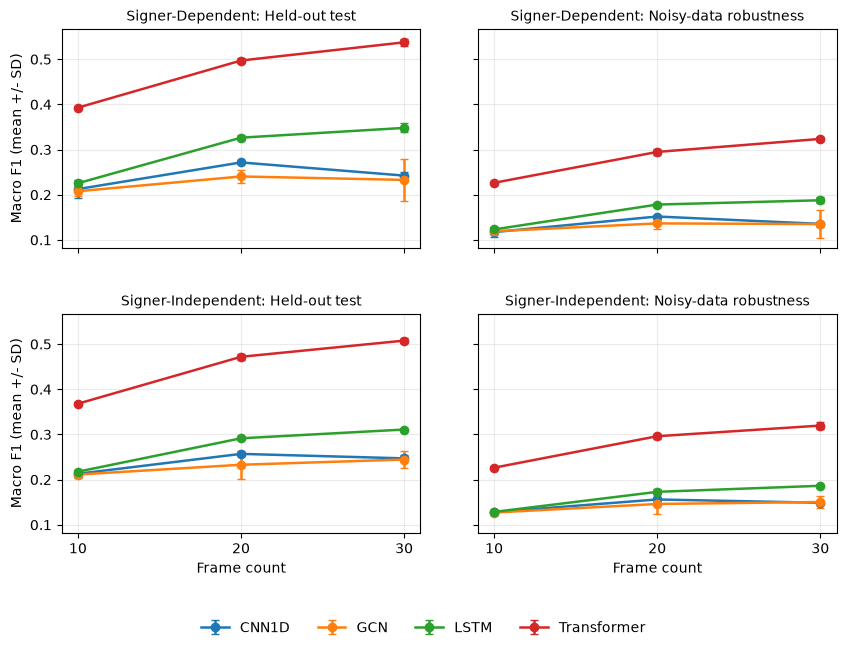

In [41]:
comparison = test_by_frame.merge(
    robustness_summary,
    on=['scenario', 'model', 'frame_sample_count'],
    suffixes=('_test', '_robustness'),
).assign(
    accuracy_change=lambda frame: frame['accuracy_mean_robustness'] - frame['accuracy_mean_test'],
    f1_change=lambda frame: frame['f1_score_mean_robustness'] - frame['f1_score_mean_test'],
)

robustness_change = comparison[[
    'scenario', 'model', 'frame_sample_count', 'accuracy_change', 'f1_change'
]].sort_values(['scenario', 'model', 'frame_sample_count'])
display(robustness_change)

significant_pairs = pairwise_stats.loc[
    pairwise_stats['paired_t_holm_p'].lt(0.05),
    ['scenario', 'frame_sample_count', 'metric', 'model_a', 'model_b',
     'mean_difference_a_minus_b', 'cohens_dz', 'paired_t_holm_p', 'wilcoxon_holm_p']
]
display(significant_pairs)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for row_index, scenario in enumerate(['sd', 'si']):
    subset = comparison.loc[comparison['scenario'].eq(scenario)]
    for column_index, (source, title) in enumerate([
        ('test', 'Held-out test'),
        ('robustness', 'Noisy-data robustness'),
    ]):
        axis = axes[row_index, column_index]
        for model in MODEL_ORDER:
            values = subset.loc[subset['model'].eq(model)].sort_values('frame_sample_count')
            mean_column = f'f1_score_mean_{source}'
            sd_column = 'f1_score_std' if source == 'test' else 'f1_score_sd'
            axis.errorbar(
                values['frame_sample_count'], values[mean_column], yerr=values[sd_column],
                marker='o', capsize=3, linewidth=1.8, label=MODEL_LABELS[model],
            )
        axis.set_title(f'{SCENARIO_LABELS[scenario]}: {title}', fontsize=10)
        axis.set_xticks(FRAME_ORDER)
        axis.grid(alpha=0.25)
        if row_index == 1:
            axis.set_xlabel('Frame count')
        if column_index == 0:
            axis.set_ylabel('Macro F1 (mean +/- SD)')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False)
fig.subplots_adjust(bottom=0.16, hspace=0.3, wspace=0.16)
fig.savefig(OUTPUT_DIR / 'figure_4_clean_vs_robustness_f1.png', dpi=300, bbox_inches='tight')
plt.show()

## Training and validation loss by seed

For each model, the six panels cover SD/SI and 10/20/30 frames. Each panel overlays the three seeds: lightly drawn solid lines are the recorded training losses, and bold dashed lines are validation losses. Validation checkpoints are placed proportionally along their run's recorded training-update axis, preserving runs that stopped at different points.

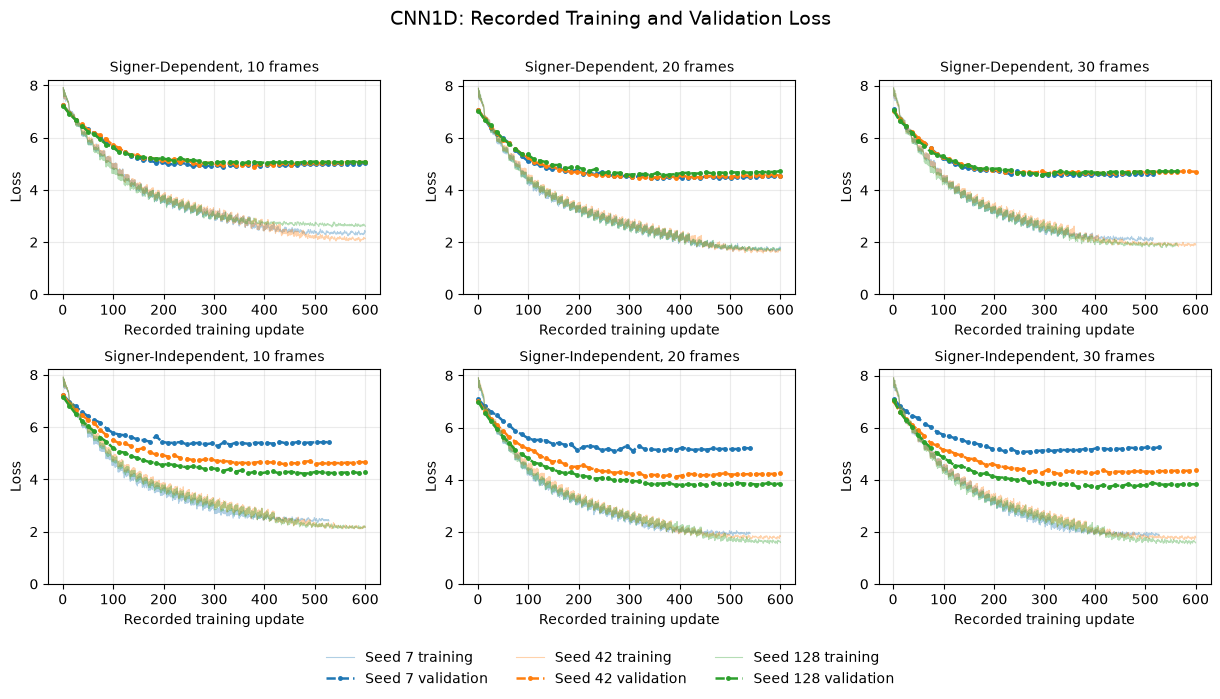

Wrote training_validation_loss_cnn1d.png


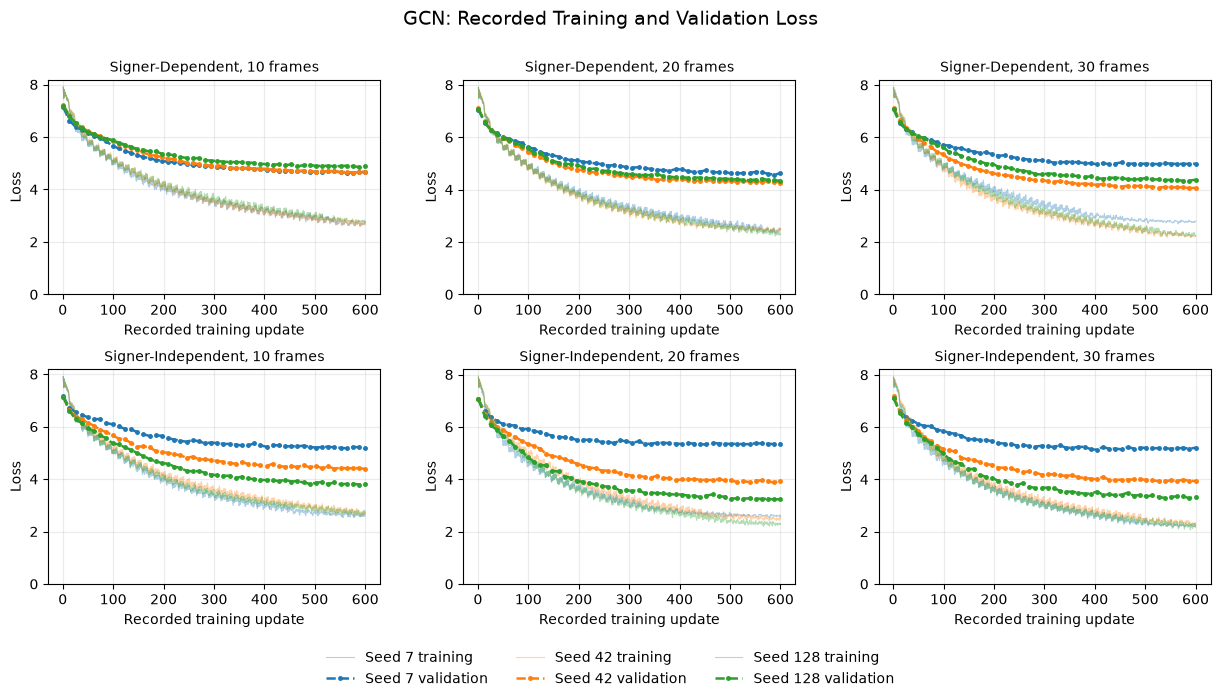

Wrote training_validation_loss_gcn.png


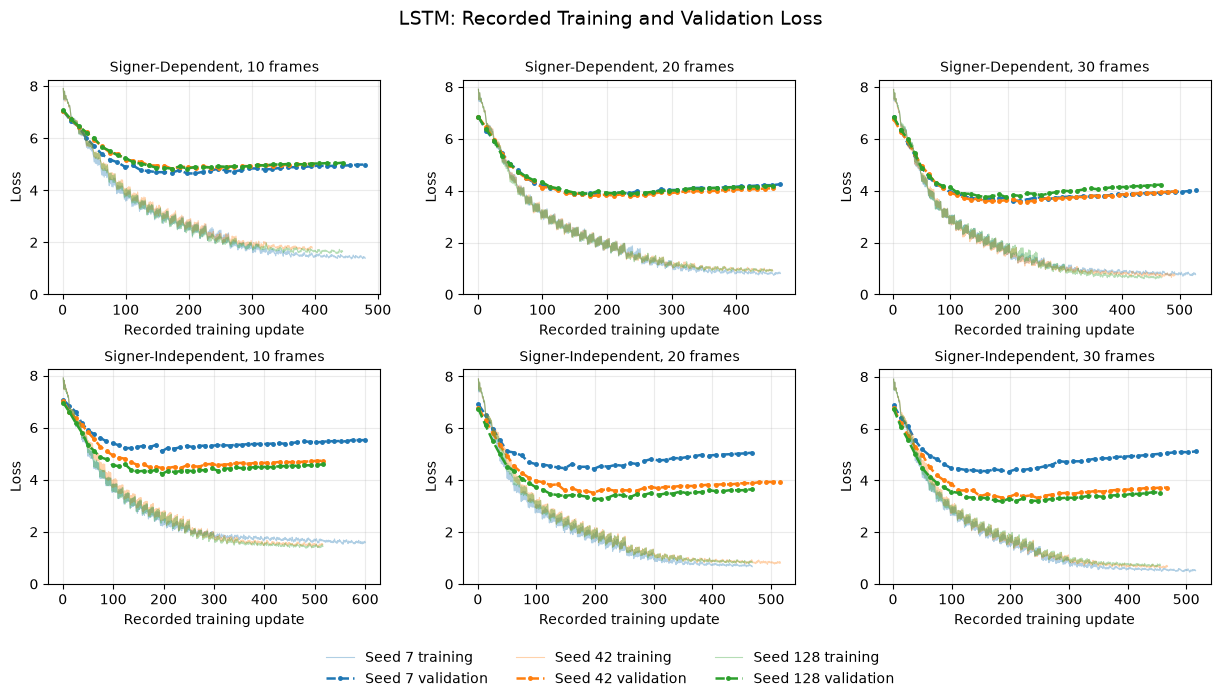

Wrote training_validation_loss_lstm.png


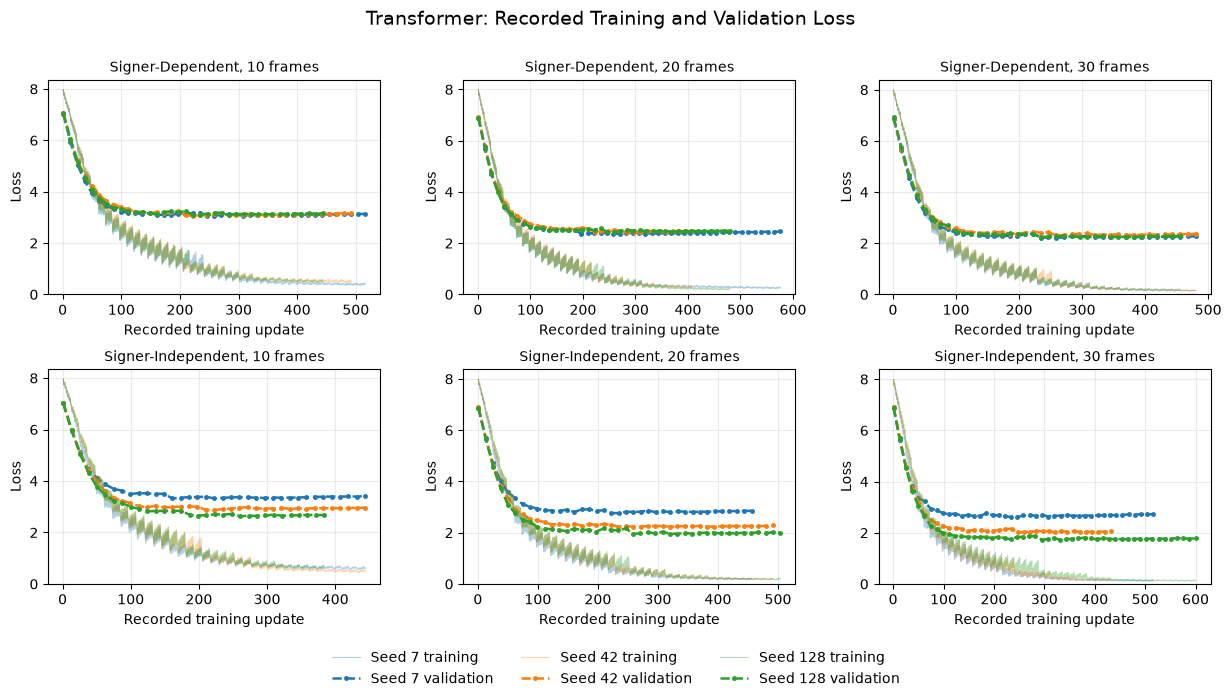

Wrote training_validation_loss_transformer.png


In [42]:
SEED_COLORS = {7: '#1f77b4', 42: '#ff7f0e', 128: '#2ca02c'}

for model in MODEL_ORDER:
    fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=False, sharey=False)
    for row_index, scenario in enumerate(['sd', 'si']):
        for column_index, frame_count in enumerate(FRAME_ORDER):
            axis = axes[row_index, column_index]
            panel_runs = test_runs.loc[
                test_runs['scenario'].eq(scenario)
                & test_runs['model'].eq(model)
                & test_runs['frame_sample_count'].eq(frame_count)
            ].sort_values('seed')
            for run in panel_runs.itertuples(index=False):
                history = run_histories[run.run_dir]
                train_loss = np.asarray(history['loss'], dtype=float)
                validation_loss = np.asarray(history['val_loss'], dtype=float)
                train_x = np.arange(1, len(train_loss) + 1)
                validation_x = np.linspace(1, len(train_loss), len(validation_loss))
                color = SEED_COLORS[int(run.seed)]
                axis.plot(train_x, train_loss, color=color, alpha=0.35, linewidth=0.8,
                          label=f'Seed {run.seed} training')
                axis.plot(validation_x, validation_loss, color=color, linestyle='--', linewidth=1.8,
                          marker='o', markersize=2.5, label=f'Seed {run.seed} validation')
            axis.set_title(f"{SCENARIO_LABELS[scenario]}, {frame_count} frames", fontsize=10)
            axis.set_xlabel('Recorded training update')
            axis.set_ylabel('Loss')
            axis.set_ylim(bottom=0)
            axis.grid(alpha=0.25)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    unique_handles, unique_labels = [], []
    for handle, label in zip(handles, labels):
        if label not in unique_labels:
            unique_handles.append(handle)
            unique_labels.append(label)
    fig.suptitle(f"{MODEL_LABELS[model]}: Recorded Training and Validation Loss", fontsize=14)
    fig.legend(unique_handles, unique_labels, loc='lower center', ncol=3, frameon=False)
    fig.subplots_adjust(bottom=0.16, top=0.88, hspace=0.35, wspace=0.25)
    output_path = OUTPUT_DIR / f"training_validation_loss_{model}.png"
    fig.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Wrote {output_path.name}')

## Training and validation Accuracy and Macro F1 by seed

These plots use the same panel layout and seed colors as the loss figures. Scores are constrained to the 0-1 range; solid lines are training metrics and dashed lines are validation metrics.

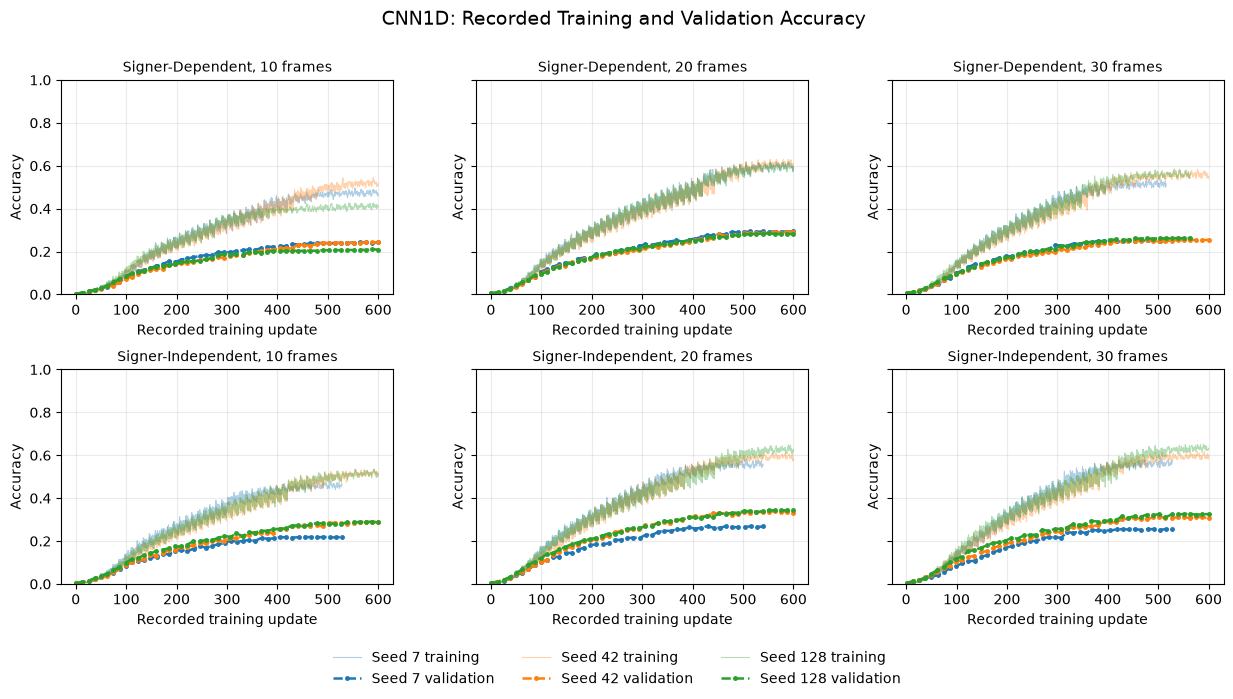

Wrote training_validation_accuracy_cnn1d.png


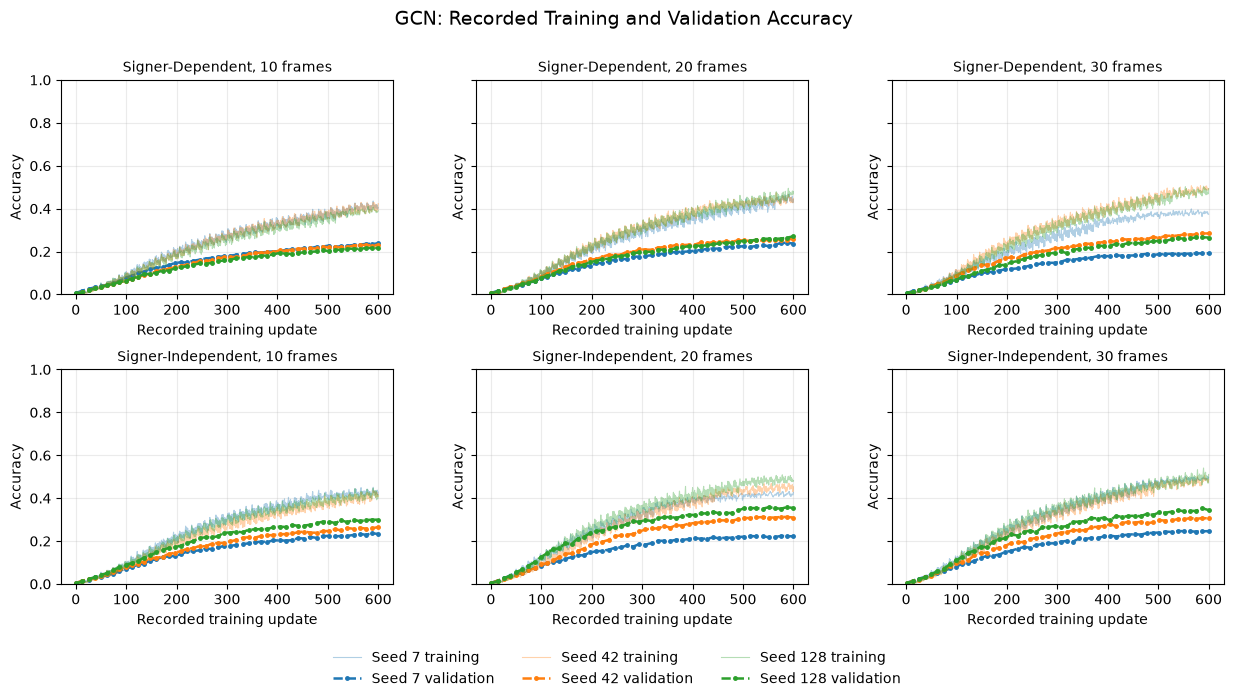

Wrote training_validation_accuracy_gcn.png


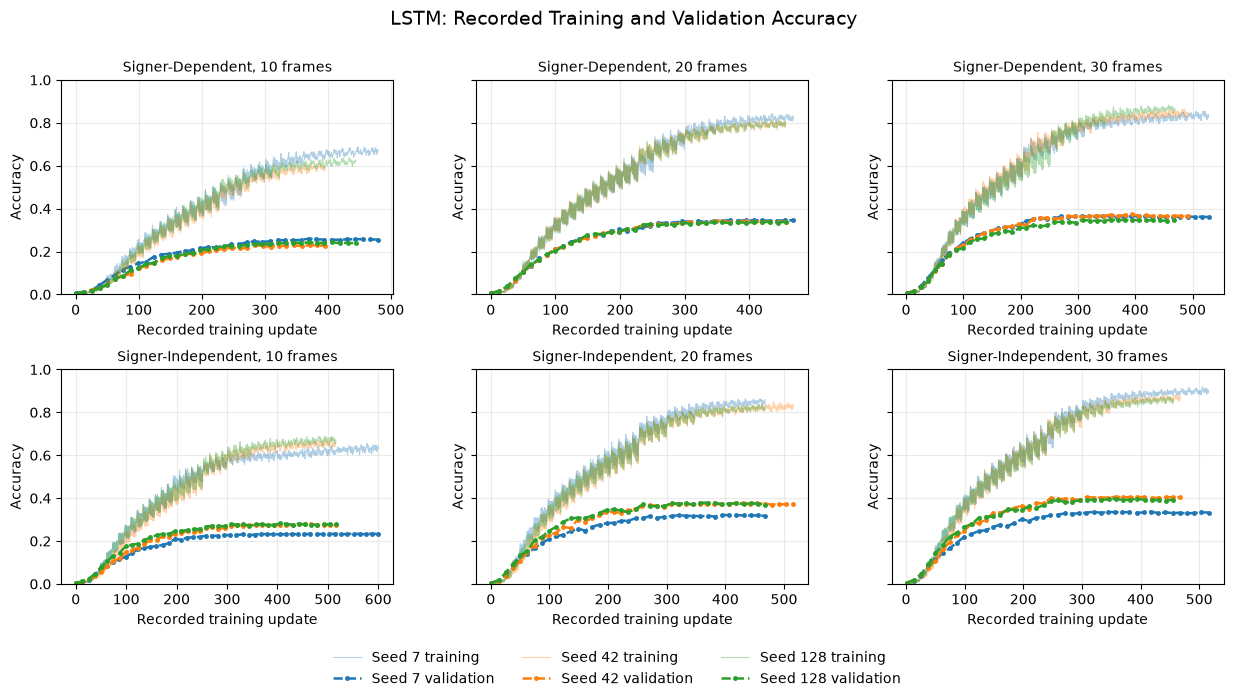

Wrote training_validation_accuracy_lstm.png


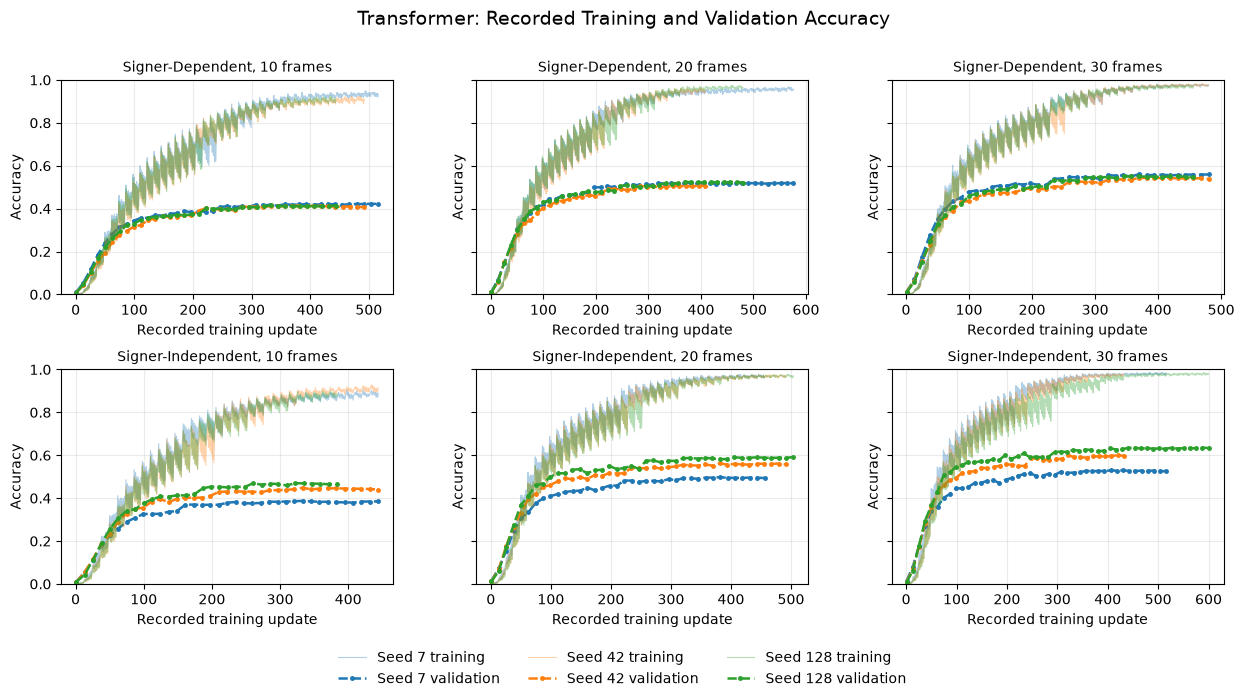

Wrote training_validation_accuracy_transformer.png


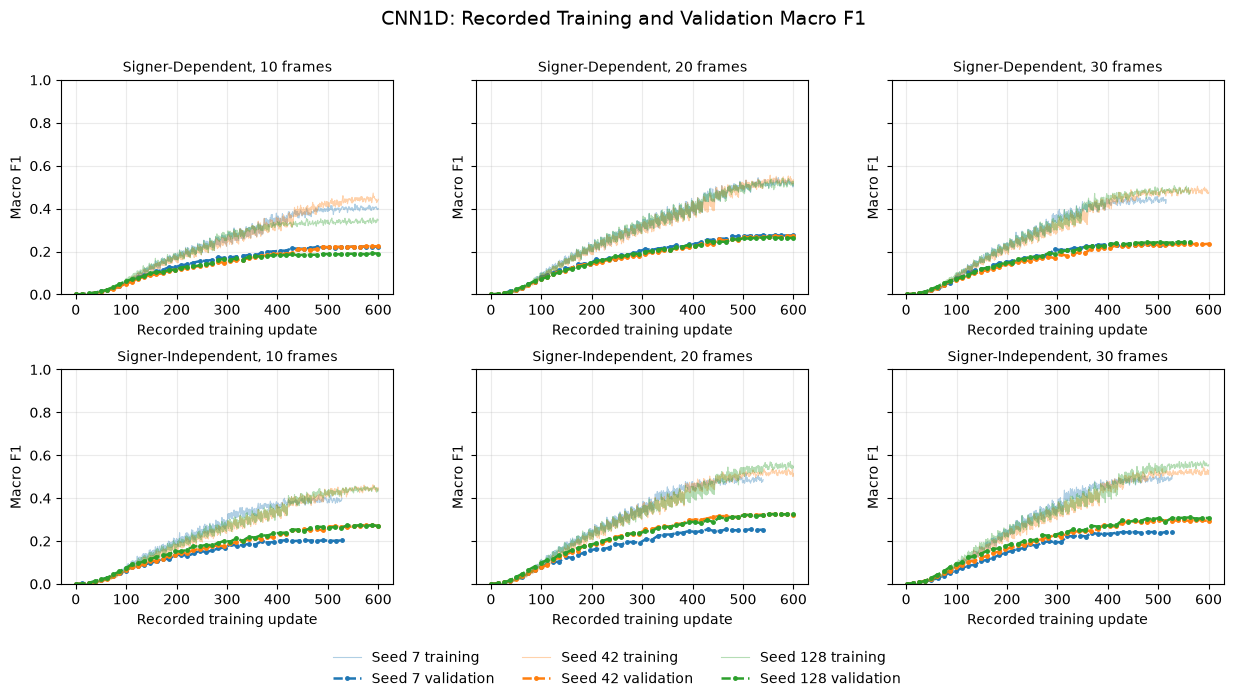

Wrote training_validation_f1_score_cnn1d.png


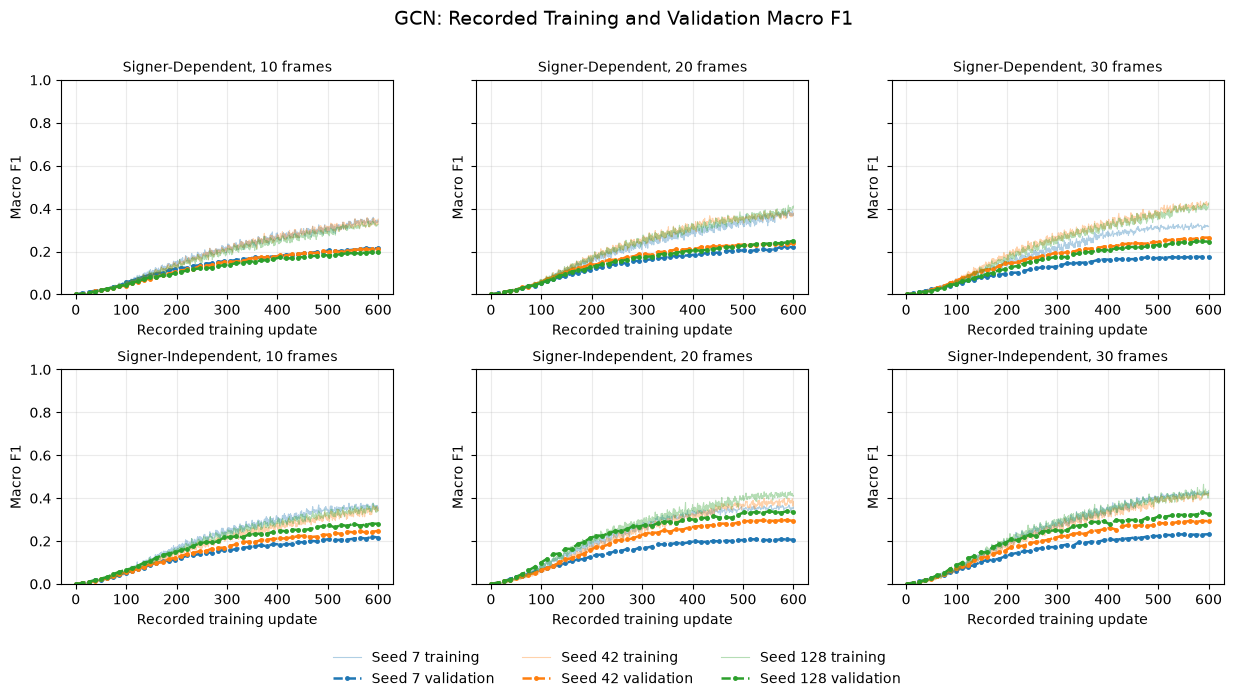

Wrote training_validation_f1_score_gcn.png


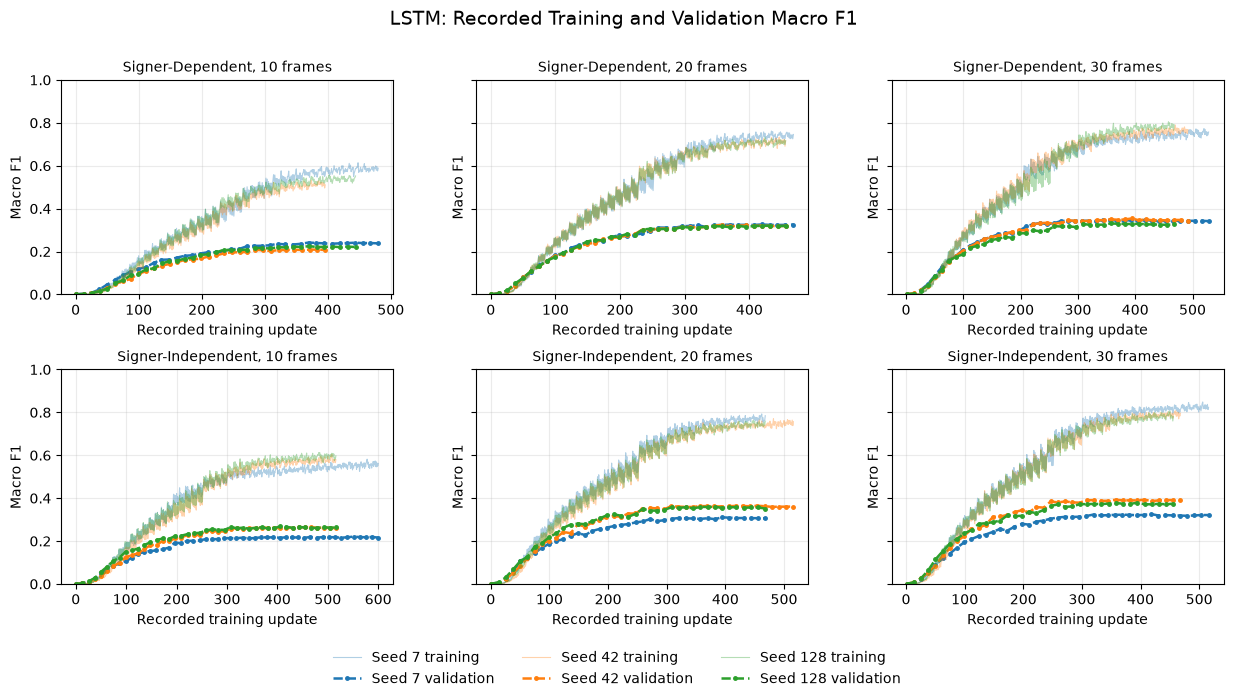

Wrote training_validation_f1_score_lstm.png


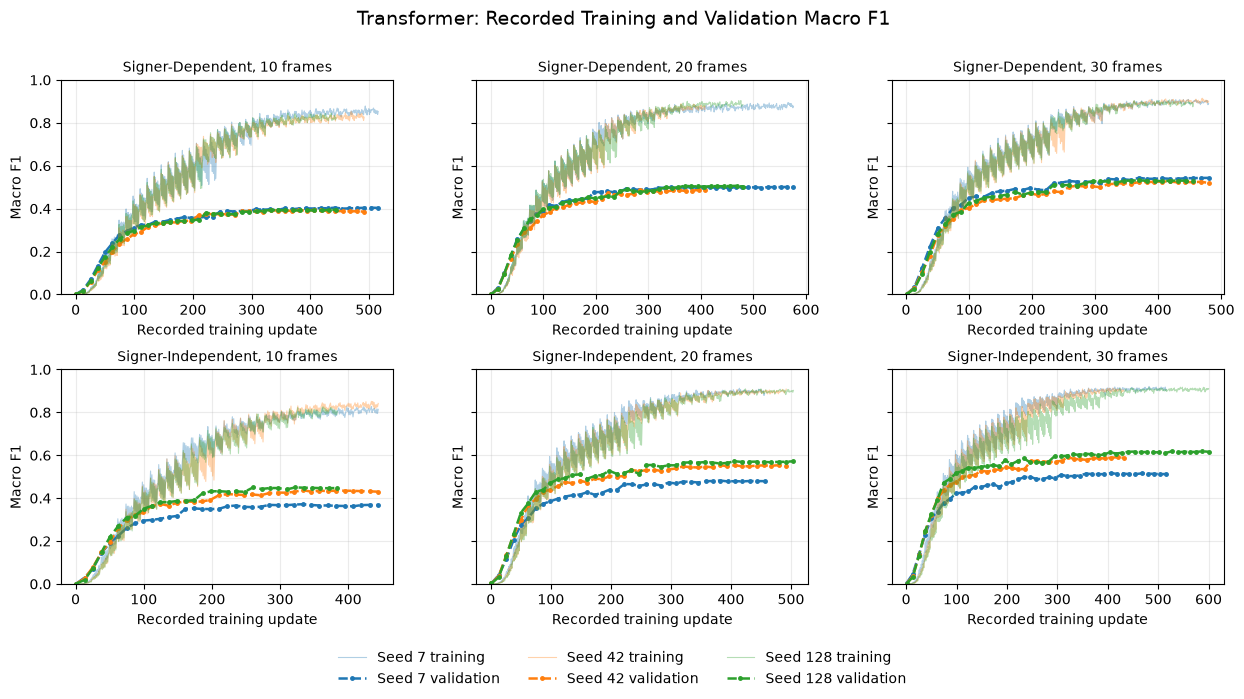

Wrote training_validation_f1_score_transformer.png


In [43]:
for metric, metric_label in [('accuracy', 'Accuracy'), ('f1_score', 'Macro F1')]:
    for model in MODEL_ORDER:
        fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=False, sharey=True)
        for row_index, scenario in enumerate(['sd', 'si']):
            for column_index, frame_count in enumerate(FRAME_ORDER):
                axis = axes[row_index, column_index]
                panel_runs = test_runs.loc[
                    test_runs['scenario'].eq(scenario)
                    & test_runs['model'].eq(model)
                    & test_runs['frame_sample_count'].eq(frame_count)
                ].sort_values('seed')
                for run in panel_runs.itertuples(index=False):
                    history = run_histories[run.run_dir]
                    training_values = np.asarray(history[metric], dtype=float)
                    validation_values = np.asarray(history[f'val_{metric}'], dtype=float)
                    training_x = np.arange(1, len(training_values) + 1)
                    validation_x = np.linspace(1, len(training_values), len(validation_values))
                    color = SEED_COLORS[int(run.seed)]
                    axis.plot(training_x, training_values, color=color, alpha=0.35, linewidth=0.8,
                              label=f'Seed {run.seed} training')
                    axis.plot(validation_x, validation_values, color=color, linestyle='--', linewidth=1.8,
                              marker='o', markersize=2.5, label=f'Seed {run.seed} validation')
                axis.set_title(f"{SCENARIO_LABELS[scenario]}, {frame_count} frames", fontsize=10)
                axis.set_xlabel('Recorded training update')
                axis.set_ylabel(metric_label)
                axis.set_ylim(0, 1)
                axis.grid(alpha=0.25)
        handles, labels = axes[0, 0].get_legend_handles_labels()
        unique_handles, unique_labels = [], []
        for handle, label in zip(handles, labels):
            if label not in unique_labels:
                unique_handles.append(handle)
                unique_labels.append(label)
        fig.suptitle(f"{MODEL_LABELS[model]}: Recorded Training and Validation {metric_label}", fontsize=14)
        fig.legend(unique_handles, unique_labels, loc='lower center', ncol=3, frameon=False)
        fig.subplots_adjust(bottom=0.16, top=0.88, hspace=0.35, wspace=0.25)
        output_path = OUTPUT_DIR / f"training_validation_{metric}_{model}.png"
        fig.savefig(output_path, dpi=300, bbox_inches='tight')
        plt.show()
        print(f'Wrote {output_path.name}')

## Export publication-supporting tables

The exported workbook contains presentation tables, seed-level source rows, and the exploratory paired comparison results.

In [44]:
exports = {
    'table_ii_10frame_test': table_ii_10,
    'table_iv_frame_comparison': table_iv_frame,
    'training_testing_by_seed': training_testing_by_seed,
    'training_testing_summary': training_testing_summary,
    'table_iii_10frame_latency': table_iii_latency,
    'table_v_latency_by_frame': table_v_latency,
    'table_vi_robustness': table_vi_robustness,
    'test_summary_by_frame': test_by_frame,
    'robustness_summary_by_frame': robustness_summary,
    'inference_latency_by_seed': latency_by_seed,
    'inference_latency_summary': latency_summary,
    'robustness_change': robustness_change,
    'pairwise_stats': pairwise_stats,
    'selected_test_runs': test_runs,
    'robustness_runs': robustness_runs,
}

for name, frame in exports.items():
    frame.to_csv(OUTPUT_DIR / f'{name}.csv', index=False)

workbook_path = OUTPUT_DIR / 'sd_si_hand_3seed_report.xlsx'
with pd.ExcelWriter(workbook_path, engine='openpyxl') as writer:
    for name, frame in exports.items():
        frame.to_excel(writer, sheet_name=name[:31], index=False)

print(f'Wrote {len(exports)} CSV tables and {workbook_path}')

Wrote 15 CSV tables and /app/artifacts/final_reports/sd_si_hand_3seed_report.xlsx
